In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")
from src.strategies import run_momentum_strategy
from src.backtester import calculate_return

df = pd.read_csv("../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252
transaction_cost = 0.001

In [2]:
_, momentum_results = run_momentum_strategy(prices, returns, lookback, transaction_cost)
print(pd.Series(momentum_results))

total_return          5.400420
cagr                  0.075102
annual_volatility     0.128810
annual_sharpe         0.627024
max_drawdown         -0.315812
calmar                0.237805
time_invested         0.775232
trades               89.000000
dtype: float64


In [3]:
df1 = pd.read_csv("../data/elementary_random_strategy_summary.csv")
df2 = pd.read_csv("../data/exposure_matched_random_strategy_summary.csv")
df3 = pd.read_csv("../data/trade_count_matched_random_strategy_summary.csv")
df4 = pd.read_csv("../data/exposure_+_trade_count_matched_random_strategy_summary.csv")
df5 = pd.read_csv("../data/run_length_permutation_random_strategy_summary.csv")
df6 = pd.read_csv("../data/cyclic_shift_random_strategy_summary.csv")


In [4]:
frames = [df1, df2, df3, df4, df5, df6]

results = pd.concat(frames, ignore_index = True)

results.columns = results.columns.str.title().str.replace("_", " ")

results["Strategy"] = (
    results["Strategy"]
    .str.replace("_random_strategy", "")
    .str.replace("_", " ")
    .str.title()
)

results

,Strategy,Mean Sharpe,Median Sharpe,Max Sharpe,P Value,Avg Trades,Avg Time Invested,Number Of Simulations
0,Elementary,-0.542481,-0.542160,0.092003,0.000010,3229.84590,0.500002,100000
1,Exposure Matched,-0.036150,-0.036469,0.380730,0.000010,2251.87858,0.775208,100000
2,Trade Count Matched,0.375792,0.370519,1.010502,0.036490,89.00000,0.499999,100000
3,Exposure + Trade Count Matched,0.469425,0.464082,0.946090,0.047090,89.00000,0.775232,100000
4,Run Length Permutation,0.473815,0.460054,0.984638,0.077839,89.00000,0.775232,100000
5,Cyclic Shift,0.473505,0.442368,1.181052,0.110169,90.76216,0.775232,100000


In [5]:
table = results.copy()

table = table.round({
    "Mean Sharpe": 4,
    "Median Sharpe": 4,
    "Max Sharpe": 4,
    "P Value": 5,
    "Avg Trades": 2,
    })

table["Avg Time Invested"] = table["Avg Time Invested"].map(
    lambda x: f"{x * 100:.2f}%"
)

table

,Strategy,Mean Sharpe,Median Sharpe,Max Sharpe,P Value,Avg Trades,Avg Time Invested,Number Of Simulations
0,Elementary,-0.5425,-0.5422,0.0920,0.00001,3229.85,50.00%,100000
1,Exposure Matched,-0.0361,-0.0365,0.3807,0.00001,2251.88,77.52%,100000
2,Trade Count Matched,0.3758,0.3705,1.0105,0.03649,89.00,50.00%,100000
3,Exposure + Trade Count Matched,0.4694,0.4641,0.9461,0.04709,89.00,77.52%,100000
4,Run Length Permutation,0.4738,0.4601,0.9846,0.07784,89.00,77.52%,100000
5,Cyclic Shift,0.4735,0.4424,1.1811,0.11017,90.76,77.52%,100000


In [7]:
print(table.to_markdown(index=False))

| Strategy                       |   Mean Sharpe |   Median Sharpe |   Max Sharpe |   P Value |   Avg Trades | Avg Time Invested   |   Number Of Simulations |
|:-------------------------------|--------------:|----------------:|-------------:|----------:|-------------:|:--------------------|------------------------:|
| Elementary                     |       -0.5425 |         -0.5422 |       0.092  |   1e-05   |      3229.85 | 50.00%              |                  100000 |
| Exposure Matched               |       -0.0361 |         -0.0365 |       0.3807 |   1e-05   |      2251.88 | 77.52%              |                  100000 |
| Trade Count Matched            |        0.3758 |          0.3705 |       1.0105 |   0.03649 |        89    | 50.00%              |                  100000 |
| Exposure + Trade Count Matched |        0.4694 |          0.4641 |       0.9461 |   0.04709 |        89    | 77.52%              |                  100000 |
| Run Length Permutation         |        0.47

## Interpretation

The momentum strategy being benchmarked returned an observed annualized Sharpe ratio of approx. 0.627. The strategy was invested in the SPY around 77.52% of the time, with 89 trades occuring across the time period. 



1. Elementary Random Benchmark - $H_0$(1): Momentum's risk-adjusted performance is consistent with a independently random 50/50 market-timing strategy. 

    In the Elementary random strategy, each valid trading day has a 50% chance of being in an invested/cash state. 

    Momentum substantially outperforms this simplistic benchmark on a risk-adjusted basis; in fact, Momentum's annualized Sharpe ratio exceeds the maximum Sharpe observed across all 100,000 simulated strategies by 0.5350. Using the correct empirical estimator gives p ≈ 0.00001, providing very strong evidence against $H_0$(1). 


2. Exposure-Matched Random Benchmark - $H_0$(2): Momentum's risk-adjusted performance is consistent with an independently random exposure-matched market-timing strategy.

    The Exposure-Matched random strategy controls for the proportion of valid trading days spent invested in SPY. Each valid trading day has an approx. 77.52% chance of being in an invested state. Indeed, the average time invested across the Exposure-Matched simulations ends up at the 77.52% mark. 

    Momentum exceeds the mean Exposure-Matched Sharpe ratio by 0.6631. With an empirical p-value of p ≈ 0.00001, there is very strong evidence to reject $H_0$(2). 


3. Trade-Count Matched Random Benchmark - $H_0$(3): Momentum's risk-adjusted performance is consistent with a strategy containing 89 randomly selected positions switches.

    Strategies 1. and 2. are punished by the large volume of trades occuring and the transaction costs these trades incur. This benchmark aims to resolve this by matching the number of position changes occuring with Momentum (89). The switch dates are sampled uniformly, without replacement. The split between time invested/time in cash is approx. 50/50. 

    Momentum achieved materially stronger risk-adjusted performance than the benchmark, outperforming the mean Sharpe ratio by 0.2512. A p-value of 0.03649 provides evidence against the null, so we reject $H_0$(3) at the 5% significance level. 

    The substantial upshift in benchmark Sharpe distribution is consistent with excessive turnover (and assosciated transaction costs) materially depressing earlier benchmarks. However, constraing the number of position changes allows greater persistence of an invested/cash run in the signal. Thus, effect cannot be contributed solely to transaction costs. 


4. Exposure + Trade-Count Matched Random Benchmark - $H_0$(4): Momentum's risk-adjusted performance is consistent with a strategy containing 89 randomly selected position switches and exposure-matched market-timing.

    This benchmark aims to resemble the Momentum signal, by matching both trade count and exposure in the same random strategy. This is demonstrated, with every simulated strategy containing the exact proportion of invested/cash days and the same 89 position changes. 

    With an empirical p-value ≈ 0.04709, narrowly reject $H_0$(4) at the 5% significance level. There is slight evidence to suggest inconsistencies in risk-adjusted performance between momentum and a trade-count matched/exposure matched random benchmark. Notably, evidence against $H_0$ has weakened consistently as the random benchmarks more closely resemble Momentum's structure. 


5. Run Length Permutation Random Benchmark - $H_0$(5): Momentum's risk-adjusted performance is consistent with random permutations of its cash and invested run lengths. 

    This random strategy preserves the exact collection of cash and invested run lengths while randomising their ordering within each state. Consequently, exposure, trade-count and run length distribution are preserved, while temporal arrangement of runs is randomised. This signal follows Momentum's structure closer than any prior. 
    
    Momentum's Sharpe exceeds the average run length permutation by 0.1532. However, an empirical p-value of 0.07784 fails to reject the null hypothesis at the 5% significance level. There is insufficient evidence to conclude that momentum outperforms a random permutation of its own cash and invested runs. 


6. Cyclic Shifting Random Benchmark - $H_0$(6): Momentum's risk-adjusted performance is consistent with the same trading pattern shifted to different points in market history. 

    The cyclic-shift benchmark preserves ordering and local clustering of Momentum's position sequence. The signal is shifted in time by a random amount, changing which market returns the positions line up with, while retaining interal temporal structure. 

    A p-value of 0.11017 is obtained, thus we fail to reject $H_0$(6) at the 5% signficance level. There is insufficient evidence to suggest that momentum outperforms a cyclic shift of its own trading signal through market history. 

In [ ]:
results.to_csv("../data/final_benchmark_results.csv", index=False)
table.to_csv("../data/final_comparison_table.csv", index=False)

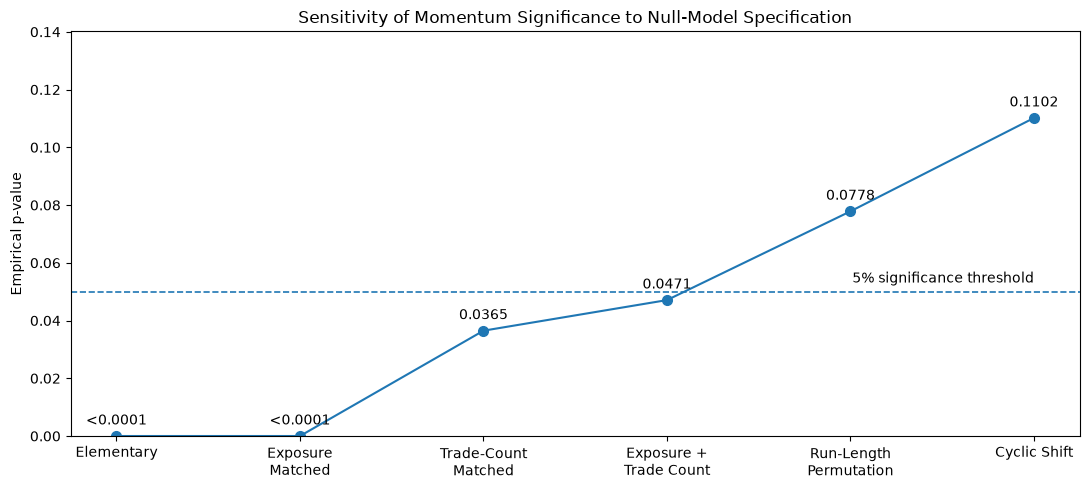

In [ ]:
import matplotlib.pyplot as plt

plot_df = table.copy()

# Numeric x positions
x = range(len(plot_df))
y = plot_df["P Value"]

# Cleaner multiline labels
labels = [
    "Elementary",
    "Exposure\nMatched",
    "Trade-Count\nMatched",
    "Exposure +\nTrade Count",
    "Run-Length\nPermutation",
    "Cyclic Shift"
]

plt.figure(figsize=(11, 5))

# Connected points
plt.plot(
    x,
    y,
    marker="o",
    markersize=7,
    linewidth=1.5
)

# 5% significance threshold
plt.axhline(
    0.05,
    linestyle="--",
    linewidth=1.2
)

# Threshold label
plt.text(
    len(labels) - 1,
    0.052,
    "5% significance threshold",
    ha="right",
    va="bottom"
)

# Annotate p-values
for i, p in enumerate(y):
    label = "<0.0001" if p < 0.0001 else f"{p:.4f}"

    plt.text(
        i,
        p + 0.004,
        label,
        ha="center"
    )

plt.title("Sensitivity of Momentum Significance to Null-Model Specification")
plt.ylabel("Empirical p-value")

plt.xticks(
    x,
    labels,
    rotation=0
)

plt.ylim(0, max(y) + 0.03)

plt.tight_layout()
plt.show()

Figure: Empirical one-sided p-values for the observed momentum Sharpe under increasingly structure-preserving null models. The dashed line marks the 5% significance threshold; evidence against the null weakens as more of the strategy’s structure is preserved.